# Mathematical Analysis and Dynamic Active Subspaces for a Long Term Model of HIV

__Tyson Loudon__, School of Mathematics, University of Minnesota-Twin Cities

__Stephen Pankavich__, Department of Applied Mathematics and Statistics, Colorado School of Mines

__Ryan Howard__ (2016 notebook and data)

<br>

> **Link moved.** The published paper (Math. Biosci. Eng. 14(3), 2017, p. 710) links to this notebook at `nbviewer.org/github/paulcon/as-data-sets/blob/master/HIV/HIV.ipynb`. That link no longer works, because the repository's `master` branch was renamed to `main` in October 2026. The current notebook is at <https://nbviewer.org/github/paulcon/as-data-sets/blob/main/epidemiology_systems_biology/HIV_Long_Term_Dynamics/HIV_Long_Term_Dynamics.ipynb>, and the 2016 version is at <https://nbviewer.org/github/paulcon/as-data-sets/blob/legacy-master/HIV/HIV.ipynb>.

In this notebook, we'll be summarizing the active subspaces-based sensitivity analysis and low-dimensional approximation of an HIV model, presented in [[1]][R1]. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later (see the repository's `requirements.txt`), and takes about a minute.

### Introduction

Acquired Immune Deficiency Syndrome (AIDS) is caused by the Human Immunodeficiency Virus (HIV). One way to develop treatment strategies for this virus is through mathematical and computational models. However, most HIV models do not accurately characterize all stages of the infection, but one model recently developed does capture all three stages (acute, chronic, and AIDS). Here, we'll describe the model and use _active subspaces_ to perform sensitivity analysis on the model's parameters and explore the possibility for lowering the model's dimension.

### Active Subspaces

Active subspaces is a method of dimension reduction that identifies linear combinations of input parameters whose values are more important in characterizing a model's output than orthogonal linear combinations' values. Consider a model's scalar output, $f$, as a function of an $m$-dimensional normalized parameter vector, $\mathbf x:\ f = f(\mathbf x)$. The active subspace method is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T\rho(\mathbf x)\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\rho$ is a probability density on $\mathbf x$ and $\mathbf W\Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$, with the eigenvalues in descending order. The eigenvalues satisfy the relationship $\lambda_i = \int (\nabla f^T\mathbf w_i)^2\rho\ d\mathbf x$, meaning that an eigenvalue quantifies the average squared directional derivative of $f$ in the direction defined by the corresponding eigenvector. If the first $n < m$ eigenvalues are large compared to the rest, $f$ will likely be relatively flat in the directions defined by the last $m-n$ eigenvectors and could be approximated by an $n$-dimensional function of the active variables, $\mathbf y\equiv \mathbf W_1^T\mathbf x$, where $\mathbf W_1$ contains the first $n$ eigenvectors [[2]][R2].

Since $\mathbf C$ can't usually be computed analytically, we can approximate it with the following simple Monte Carlo method:
1. Draw $\{\mathbf x_j\}_{j=1}^N$ from $\rho$.
2. Compute (or approximate) $\nabla f_j = \nabla f(\mathbf x_j)\ \forall j$.
3. Then $\mathbf C \approx\hat{\mathbf C} = \frac 1 N \sum_{j=1}^N\nabla f_j\nabla f_j^T = \hat{\mathbf W}\hat\Lambda\hat{\mathbf W}^T$

### The HIV Model

The HIV model we examine consists of 7 coupled ordinary differential equations ([[1]][R1], Eq. (1)):

$$
\begin{align}
\frac{dT}{dt} &= s_1 + \frac{p_1}{C_1+V}TV - \delta_1T - (K_1V + K_2M_I)T,\\
\frac{dT_I}{dt} &= \psi(K_1V + K_2M_I)T + \alpha_1T_L-\delta_2T_I-K_3T_ICTL,\\
\frac{dT_L}{dt} &= (1-\psi)(K_1V+K_2M_I)T-\alpha_1T_L-\delta_3T_L,\\
\frac{dM}{dt} &= s_2+K_4MV-K_5MV-\delta_4M,\\
\frac{dM_I}{dt} &= K_5MV-\delta_5M_I-K_6M_ICTL,\\
\frac{dCTL}{dt} &= s_3 + (K_7T_I+K_8M_I)CTL-\delta_6CTL,\\
\frac{dV}{dt} &= K_9T_I+K_{10}M_I-K_{11}TV-(K_{12}+K_{13})MV-\delta_7V,
\end{align}
$$

where $T(t)$ is the CD4$^+$ T-cell population, $T_I$ is the actively infected T-cell population, $T_L$ represents latently-infected T-cells, $M$ is macrophages, $M_I$ is infected macrophages, $CTL$ is cytotoxic lymphocytes, and $V$ is virions. Time is in days. The model's 27 parameters are summarized in the table below (nominal values and units from [[1]][R1], Table 1).

Parameter|Nominal Value|Units|Distribution (U(min, max))
:-------:|:-----------:|:---:|:-------------:
$s_1$|  10 | mm$^{-3}$d$^{-1}$ | U(9.75, 10.25)
$s_2$|   .15 | mm$^{-3}$d$^{-1}$ | U(.14625, .15375)
$s_3$|   5  | mm$^{-3}$d$^{-1}$ | U(4.875, 5.125)
$p_1$|   .2 | d$^{-1}$ | U(.195, .205)
$C_1$|   55.6  | mm$^{-3}$ | U(54.21, 56.99)
$K_1$|   3.87e-3 | mm$^3$d$^{-1}$ | U(3.77325e-3, 3.96675e-3)
$K_2$|   1e-6  | mm$^3$d$^{-1}$ | U(.975e-6, 1.025e-6)
$K_3$|   4.5e-4 | mm$^3$d$^{-1}$ | U(4.3875e-4, 4.6125e-4)
$K_4$|   7.45e-4 | mm$^3$d$^{-1}$ | U(7.26375e-4, 7.63625e-4)
$K_5$|   5.22e-4 | mm$^3$d$^{-1}$ | U(5.0895e-4, 5.3505e-4)
$K_6$|   3e-6  | mm$^3$d$^{-1}$ | U(2.925e-6, 3.075e-6)
$K_7$|   3.3e-4  | mm$^3$d$^{-1}$ | U(3.2175e-4, 3.3825e-4)
$K_8$|   6e-9  | mm$^3$d$^{-1}$ | U(5.85e-9, 6.15e-9)
$K_9$|   .537 | d$^{-1}$ | U(.523575, .550425)
$K_{10}$|   .285 | d$^{-1}$ | U(.277875, .292125)
$K_{11}$|   7.79e-6 | mm$^3$d$^{-1}$ | U(7.59525e-6, 7.98475e-6)
$K_{12}$|   1e-6  | mm$^3$d$^{-1}$ | U(.975e-6, 1.025e-6)
$K_{13}$|   4e-5   | mm$^3$d$^{-1}$ | U(3.9e-5, 4.1e-5)
$\delta_1$|   .01 | d$^{-1}$ | U(.00975, .01025)
$\delta_2$|   .28  | d$^{-1}$ | U(.273, .287)
$\delta_3$|   .05  | d$^{-1}$ | U(.04875, .05125)
$\delta_4$|   .005  | d$^{-1}$ | U(.004875, .005125)
$\delta_5$|   .005 | d$^{-1}$ | U(.004875, .005125)
$\delta_6$|   .015 | d$^{-1}$ | U(.014625, .015375)
$\delta_7$|   2.39 | d$^{-1}$ | U(2.33025, 2.44975)
$\alpha_1$|   3e-4 | d$^{-1}$ | U(2.925e-4, 3.075e-4)
$\psi$|   .97 | – | U(.94575, .99425)

The limits on the uniform distributions are 2.5% above and below the nominal values ([[1]][R1], p. 718); the normalized inputs $\mathbf x\in[-1,1]^{27}$ are the affine image of these boxes ([[1]][R1], Eq. (8)). We consider T-cell count at a particular time as the model's output ($f(\mathbf x)$) and construct separate active subspaces at many points in time to examine the time-dependence of parameter importance and subspace quality.

**Initial conditions.** Every sample starts from the same state, by design: the uninfected equilibrium at the *nominal* parameters, $(s_1/\delta_1, 0, 0, s_2/\delta_4, 0, s_3/\delta_6, 0)$ ([[1]][R1], Theorem 2.1), plus one virion: $(T, T_I, T_L, M, M_I, CTL, V)(0) = (1000, 0, 0, 30, 0, 333.3, 1)$. The initial state does not change with the sampled parameters, and the paper does not state its initial conditions.

**The floor at $T = 0.1$.** Under the equations above $T$ stays positive ($dT/dt = s_1 > 0$ at $T = 0$), but in the AIDS stage it falls to very small values. The model code, from 2016, freezes the whole state once $T$ falls to $0.1$, so $T$ stays $0.1$ for the rest of the run. The paper does not have this floor. A sample at the floor at time $t$ has $\nabla f = 0$ there, since small parameter changes leave $T(t) = 0.1$.

### References:

[[1]][R1] T. Loudon and S. Pankavich. _Mathematical analysis and dynamic active subspaces for a long term model of HIV_. Math. Biosci. Eng., 14(3):709–733, 2017. doi:10.3934/mbe.2017040 (preprint arXiv:1604.04588)

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[R1]: https://doi.org/10.3934/mbe.2017040
[R2]: https://doi.org/10.1137/130916138

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

### The model code

`HIV_model.py` solves the equations with SciPy's `solve_ivp` (LSODA, relative and absolute tolerances $10^{-10}$, analytic Jacobian), and handles the floor as a terminal event at $T = 0.1$. `Tcells(p, times)` returns $T$ at the given times for each row of physical parameters `p`. One 3400-day trajectory takes less than a tenth of a second.

The data analyzed below are in three CSV files written by `generate_data.py` (see `DATA.md`), at 19 times: the 18 of the paper's Appendix B, plus $t = 1700$ days, the paper's worked example. First we check that the model reproduces the stored outputs at a few samples, and plot ten trajectories drawn from $\rho$ to illustrate the range of possible system behaviors.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import HIV_model as hm
from generate_data import TIMES, read_csv

t_start = time.perf_counter()
rng = np.random.default_rng(2017)        # the only source of randomness in this notebook

labels = [r'$s_1$', r'$s_2$', r'$s_3$', r'$p_1$', r'$C_1$', r'$K_1$', r'$K_2$', r'$K_3$',
          r'$K_4$', r'$K_5$', r'$K_6$', r'$K_7$', r'$K_8$', r'$K_9$', r'$K_{10}$',
          r'$K_{11}$', r'$K_{12}$', r'$K_{13}$', r'$\delta_1$', r'$\delta_2$',
          r'$\delta_3$', r'$\delta_4$', r'$\delta_5$', r'$\delta_6$', r'$\delta_7$',
          r'$\alpha_1$', r'$\psi$']
names = list(hm.NAMES)
space = ac.Uniform(hm.LOWER, hm.UPPER, names=names)   # nominal +- 2.5 %
half = (hm.UPPER - hm.LOWER) / 2                      # d(physical)/d(normalized)
k_of = {t: k for k, t in enumerate(TIMES)}            # column of time t

X = read_csv('inputs.csv')                            # (1000, 27) physical parameters
f = read_csv('outputs.csv')                           # (1000, 19) T(t) at TIMES
G = read_csv('gradients.csv').reshape(len(X), len(TIMES), 27)   # dT(t)/dx, normalized x
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}; times (days): {TIMES.tolist()}')
print('initial state (T, T_I, T_L, M, M_I, CTL, V)(0) =', np.round(hm.Y0, 1).tolist())

rows = [0, 1, 2, 3, 4]
T5 = hm.Tcells(X[rows], TIMES)
print(f'model vs outputs.csv, samples {rows}: max relative difference '
      f'{np.max(np.abs(T5 - f[rows]) / f[rows]):.1e}')

inputs (1000, 27), outputs (1000, 19), gradients (1000, 19, 27); times (days): [24, 38, 40, 45, 50, 55, 65, 90, 140, 500, 1000, 1600, 1700, 1800, 2000, 2200, 2400, 2800, 3400]
initial state (T, T_I, T_L, M, M_I, CTL, V)(0) = [1000.0, 0.0, 0.0, 30.0, 0.0, 333.3, 1.0]


model vs outputs.csv, samples [0, 1, 2, 3, 4]: max relative difference 1.8e-13


10 trajectories, daily output to 3400 days: 0.24 s each; 4 of 10 reach the floor T = 0.1 before t = 3400


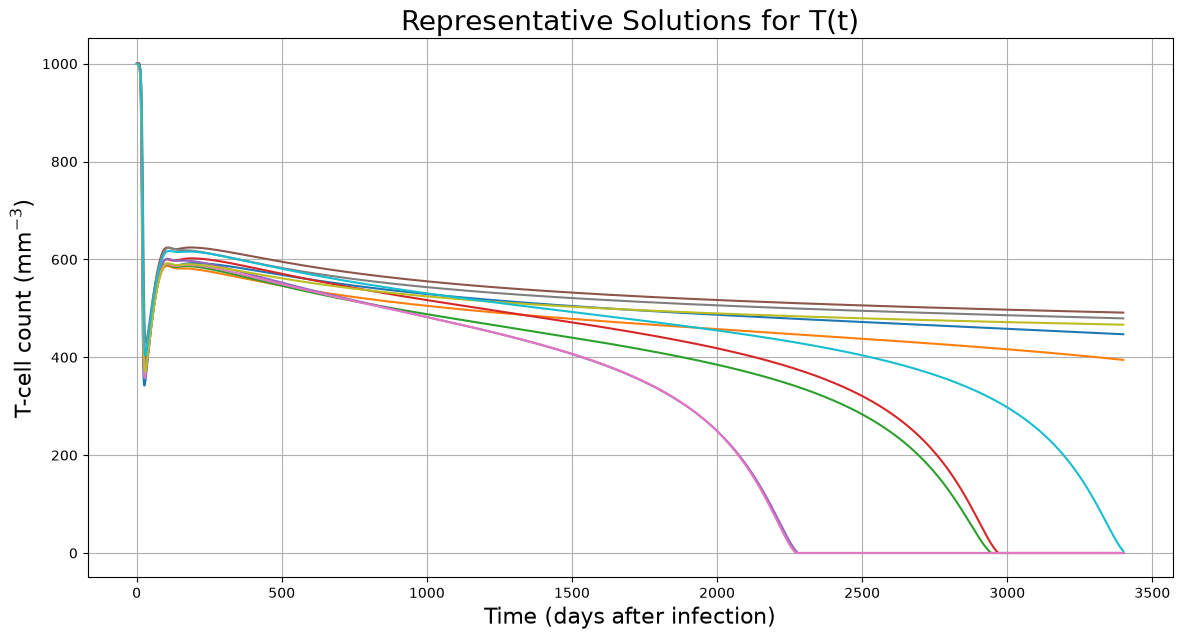

In [2]:
days = np.arange(1, 3401)
P10 = space.sample(10, rng=rng)
t0 = time.perf_counter()
T10 = hm.Tcells(P10, days)
print(f'10 trajectories, daily output to 3400 days: {(time.perf_counter() - t0) / 10:.2f} s each; '
      f'{(T10[:, -1] <= hm.T_FLOOR).sum()} of 10 reach the floor T = 0.1 before t = 3400')

plt.figure(figsize=(14, 7))
for T in T10:
    plt.plot(days, T)
plt.grid(True)
plt.xlabel('Time (days after infection)', fontsize=16)
plt.ylabel(r'T-cell count (mm$^{-3}$)', fontsize=16)
plt.title('Representative Solutions for T(t)', fontsize=20);

### A small example: finite-difference gradients for 20 samples

To show how the gradients are computed, we draw $N = 20$ samples from $\rho$ and estimate the gradients of $T$ at all 19 times by finite differences in the normalized inputs. `ac.finite_difference_gradients_multi` takes a model with several outputs, here `Tcells` at the 19 times, so one trajectory per stencil point gives all 19 gradients: forward differences with step $h = 10^{-5}$ cost $20 \times 28$ trajectories.

We then build the active subspace for $t = 24$ days and plot the estimated eigenvalues, the first eigenvector, and a one-dimensional sufficient summary plot of $T(24)$ against the first active variable, $\mathbf w_1^T\mathbf x$.

Eigenvector signs are arbitrary. v1 makes each eigenvector's largest component positive; we use `ac.orient` so that $T$ decreases along $\mathbf w_1$ (a downward trend in the summary plot, as in the 2016 notebook).

560 trajectories for 20 samples x 19 times: 64 s
N = 20, t = 24: lambda_1 = 1.048e+04, lambda_1/lambda_2 = 2934, n = 1; w1 top 4: K1 +0.51, K9 +0.50, delta7 -0.47, psi +0.47


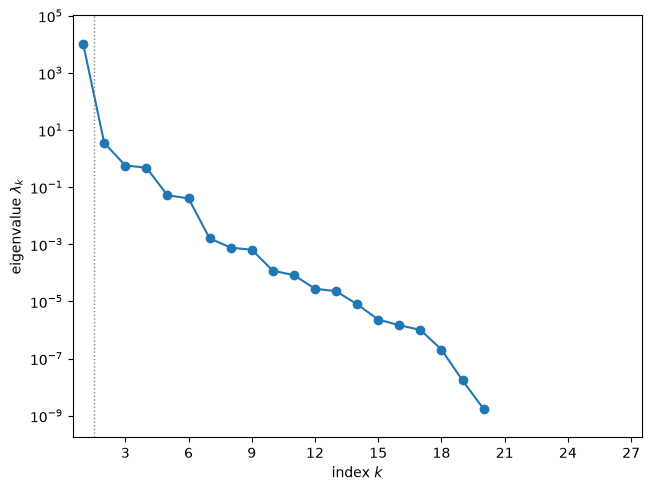

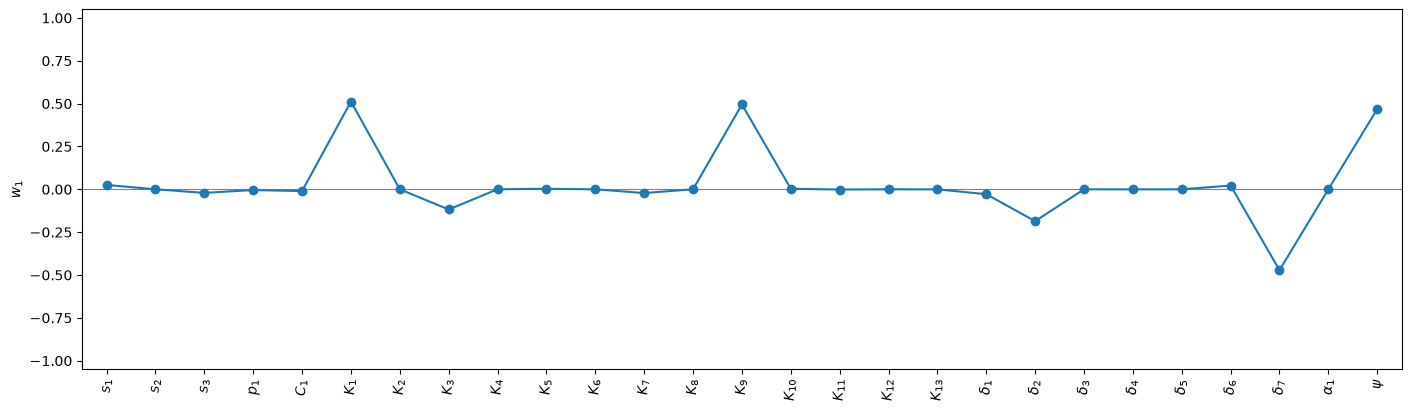

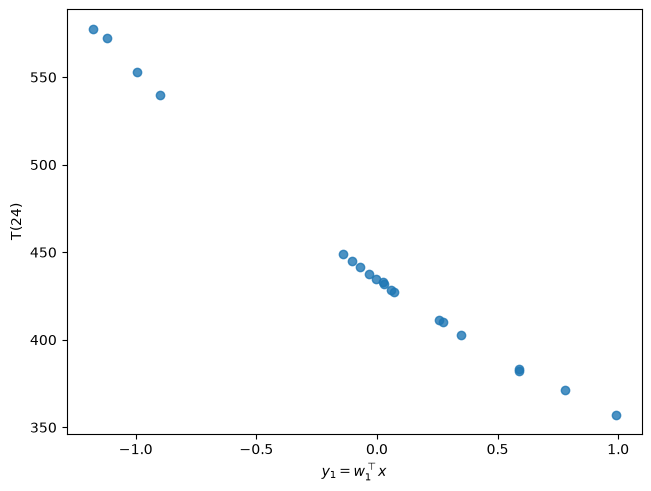

In [3]:
N = 20
P = space.sample(N, rng=rng)
t0 = time.perf_counter()
fd = ac.finite_difference_gradients_multi(lambda Q: hm.Tcells(Q, TIMES), X=P, space=space,
                                          outputs=len(TIMES), h=1e-5,
                                          qoi_names=[f'T({t})' for t in TIMES])
print(f'{fd[0].n_evaluations} trajectories for {N} samples x {len(TIMES)} times: '
      f'{time.perf_counter() - t0:.0f} s')


def top4(w):
    """The four largest-magnitude components of w, as 'name weight'."""
    return ', '.join(f'{names[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:4])


k24 = k_of[24]
sub_small = ac.orient(ac.active_subspace(grads=fd[k24]), by='covariance',
                      X=P, f=-fd[k24].values, columns=2)
lam = sub_small.eigenvalues
print(f'N = {N}, t = 24: lambda_1 = {lam[0]:.3e}, lambda_1/lambda_2 = {lam[0] / lam[1]:.0f}, '
      f'n = {sub_small.n}; w1 top 4: {top4(sub_small.W[:, 0])}')

display(ac.plotting.plot_eigenvalues(sub_small)[0])
display(ac.plotting.plot_eigenvectors(sub_small, indices=[0], labels=labels, figsize=(14, 4))[0])
display(ac.plotting.plot_sufficient_summary(sub_small, X=P, f=fd[k24].values, dims=1, qoi_label='T(24)')[0])

We see a gap between the first and second eigenvalues of several orders of magnitude, so we might expect a 1-dimensional subspace; this is confirmed by the tight univariate trend in the summary plot. The eigenvector shows that the $6^{th}$, $14^{th}$, $25^{th}$, and $27^{th}$ variables ($K_1$, $K_9$, $\delta_7$, and $\psi$, respectively) are the most important parameters for characterizing output at this time (indicated by their large weight); most of the other parameters have weight close to 0, indicating that they don't influence output very much at this time.

### 1000 samples

Twenty samples may happen to indicate an active subspace when in fact there is none. The stored data have 1000 samples of the parameters with $T$ and its gradient at the 19 times. `generate_data.py` computed them with `HIV_model.py`, central differences with step $h = 3\cdot 10^{-4}$ in the normalized inputs, and gradient 0 at the floor; that took 33 minutes on three processes (`DATA.md`), so we load the files instead. The data are a Python regeneration: the paper's results [[1]](https://doi.org/10.3934/mbe.2017040) come from MATLAB `ode23s` with forward differences of step $10^{-6}$ (pp. 717–718), which are not in this repository. `DATA.md` compares the files with the 2016 data shipped with this notebook.

At late times some samples have reached the floor. Their gradient is exactly 0, so they add nothing to $\hat{\mathbf C}$ except a weight in the average. We leave them out: each subspace below is computed from the samples above the floor at that time, so $\hat{\mathbf C}$ is the average over trajectories with $T(t) > 0.1$. (Including them would multiply every eigenvalue by the fraction above the floor and leave the eigenvectors unchanged.) The number of samples left at each time is printed below. In the summary plots, the samples at the floor are drawn in gray.

We orient $\mathbf w_1$ at $t = 24$ as above, and at each later time by `ac.orient(..., by="reference", reference=previous subspace)`, which keeps the signs continuous in time.

In [4]:
import generate_data
print(f'stored gradients: central differences, h = {generate_data.H:g} in the normalized inputs')

above = f > hm.T_FLOOR                     # (1000, 19): samples above the floor at each time
subs, prev = [], None
for k, t in enumerate(TIMES):
    sub = ac.active_subspace(space=space, grads=G[above[:, k], k] / half)  # physical gradients
    if prev is None:   # t = 24: T decreases along w1
        sub = ac.orient(sub, by='covariance', X=X, f=-f[:, k], columns=2)
    else:              # later times: signs continuous with the previous time
        sub = ac.orient(sub, by='reference', reference=prev, columns=2)
    subs.append(sub)
    prev = sub
W1 = np.array([s.W[:, 0] for s in subs])  # (19, 27) first eigenvectors, oriented

print('   t  above floor  lambda_1   l1/l2  l2/l3  n  corr(y,f)  w1: top 4')
for k, t in enumerate(TIMES):
    lam, keep = subs[k].eigenvalues, above[:, k]
    y = space.to_normalized(X[keep]) @ W1[k]
    print(f'{t:4d}  {keep.sum():6d}      {lam[0]:9.3e} {lam[0] / lam[1]:6.0f} {lam[1] / lam[2]:6.1f}  '
          f'{subs[k].n}  {np.corrcoef(y, f[keep, k])[0, 1]:+.3f}     {top4(W1[k])}')

stored gradients: central differences, h = 0.0003 in the normalized inputs
   t  above floor  lambda_1   l1/l2  l2/l3  n  corr(y,f)  w1: top 4
  24    1000      1.046e+04   3954    4.5  1  -0.990     K1 +0.51, K9 +0.49, delta7 -0.47, psi +0.47
  38    1000      8.054e+02   2319    5.4  1  -0.999     K1 +0.53, delta7 -0.49, K9 +0.47, psi +0.35
  40    1000      7.642e+02   2395    5.1  1  -0.999     K1 +0.54, delta7 -0.49, K9 +0.47, psi +0.34
  45    1000      7.000e+02   2215    5.3  1  -0.999     K1 +0.54, delta7 -0.48, K9 +0.46, psi +0.33
  50    1000      6.624e+02   2000    5.1  1  -0.999     K1 +0.55, delta7 -0.47, K9 +0.44, psi +0.32
  55    1000      6.407e+02   1895    4.4  1  -0.999     K1 +0.55, delta7 -0.46, K9 +0.43, psi +0.31
  65    1000      6.353e+02   2178    2.4  1  -0.999     K1 +0.56, delta7 -0.44, K9 +0.40, psi +0.28
  90    1000      8.393e+02   1960    2.5  1  -1.000     K1 +0.58, delta7 -0.43, K9 +0.37, s1 -0.26
 140    1000      1.238e+03   1441    6.0  1  -0.9

The eigenvalue-gap rule of v1 picks a one-dimensional subspace ($n = 1$) at every time. Here are the eigenvalues, first eigenvector and summary plot at $t = 24$ days (the acute stage) from the 1000 samples, to compare with the 20-sample plots above.

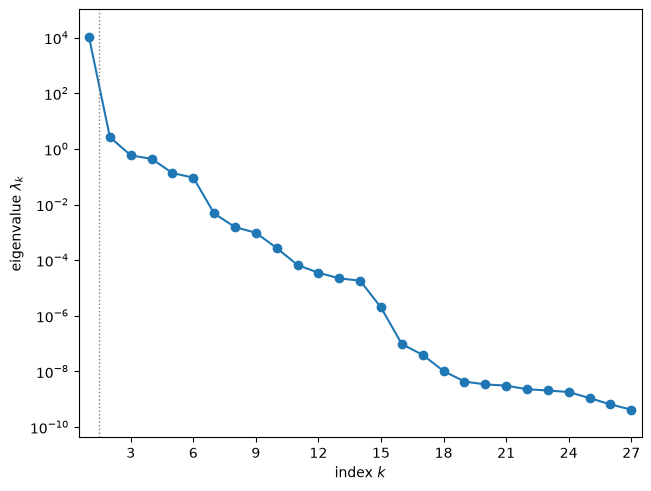

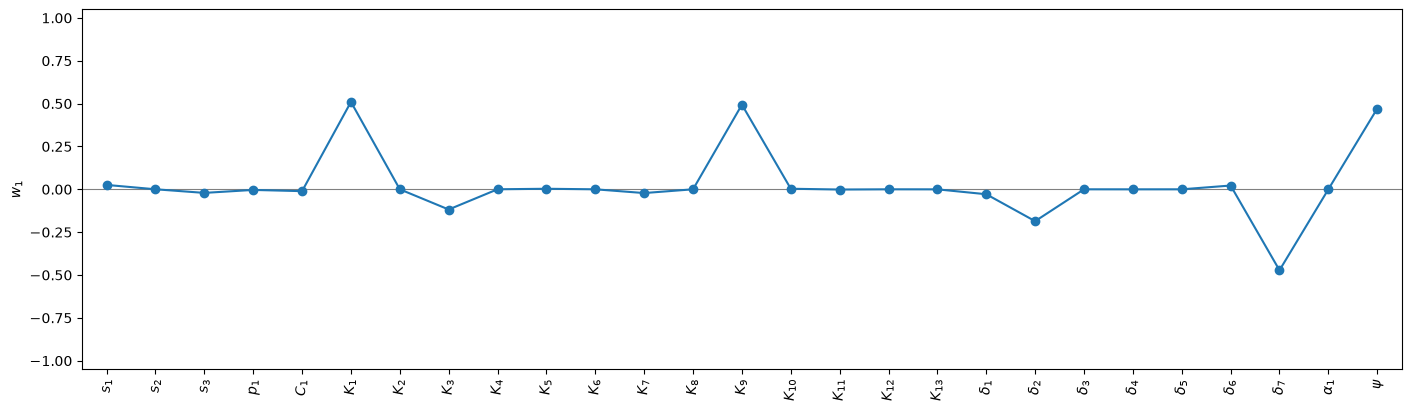

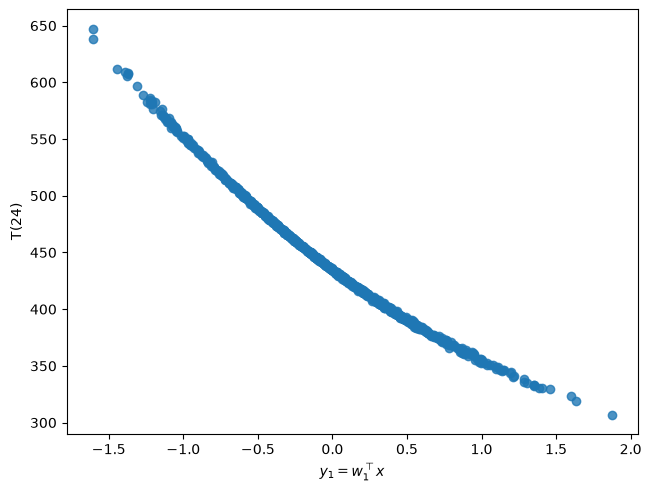

N = 20 vs N = 1000 at t = 24: lambda_1 1.048e+04 vs 1.046e+04 (ratio 1.00), |w1(20) . w1(1000)| = 1.0000


In [5]:
sub = subs[k24]
display(ac.plotting.plot_eigenvalues(sub)[0])
display(ac.plotting.plot_eigenvectors(sub, indices=[0], labels=labels, figsize=(14, 4))[0])
display(ac.plotting.plot_sufficient_summary(sub, X=X, f=f[:, k24], dims=1, qoi_label='T(24)')[0])
print(f'N = 20 vs N = 1000 at t = 24: lambda_1 {sub_small.eigenvalues[0]:.3e} vs '
      f'{sub.eigenvalues[0]:.3e} (ratio {sub_small.eigenvalues[0] / sub.eigenvalues[0]:.2f}), '
      f'|w1(20) . w1(1000)| = {abs(sub_small.W[:, 0] @ sub.W[:, 0]):.4f}')

We now construct one-dimensional sufficient summary plots for all 19 times. Samples at the floor are gray.

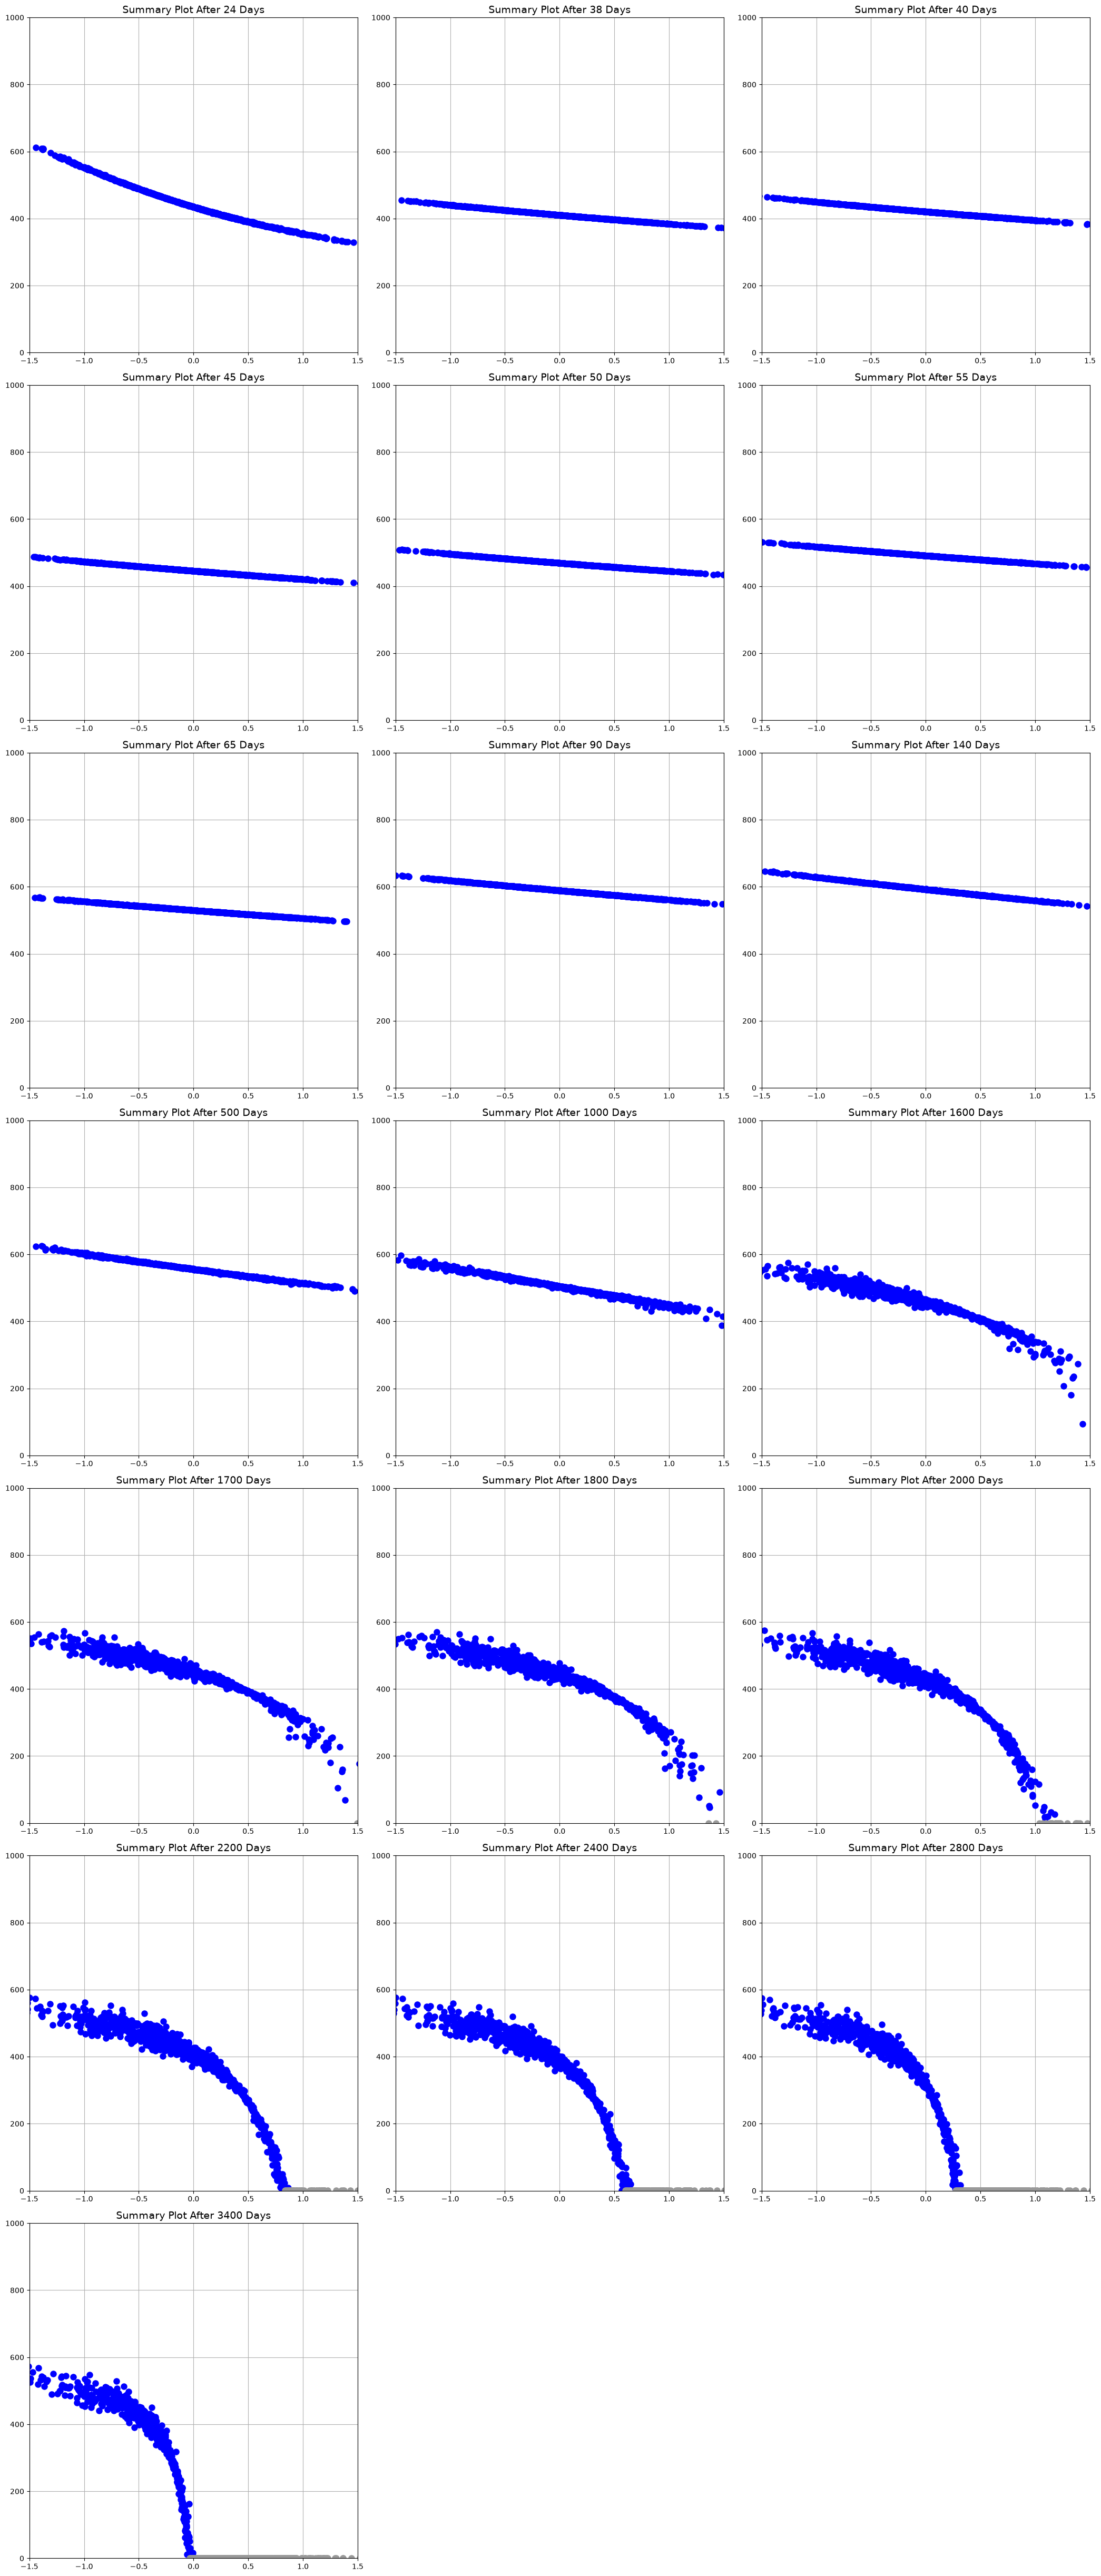

In [6]:
XX = space.to_normalized(X)
fig, axes = plt.subplots(7, 3, figsize=(21, 49))
for k, t in enumerate(TIMES):
    ax = axes.flat[k]
    y, keep = XX @ W1[k], above[:, k]
    ax.plot(y[keep], f[keep, k], 'bo', markersize=8)
    ax.plot(y[~keep], f[~keep, k], 'o', color='0.6', markersize=8)
    ax.set_xlim([-1.5, 1.5])
    ax.set_ylim([0, 1000])
    ax.grid(True)
    ax.set_title(f'Summary Plot After {t} Days', fontsize=14)
for ax in axes.flat[len(TIMES):]:
    ax.axis('off')
fig.tight_layout()
plt.show()

We can see tight univariate trends through the acute and chronic stages: $|\mathrm{corr}(y, f)|$ in the table above is at least 0.99 up to $t = 1000$. The deviation from the trend grows in the AIDS stage, as more trajectories approach $T \approx 0$. For $t \ge 1800$, [[1]](https://doi.org/10.3934/mbe.2017040) (p. 723) describes the trend as an arctangent function multiplied by a Heaviside step function: past some value of the active variable, $T$ is negligibly small. Here that region is the floor at $T = 0.1$ (the gray points), which holds 474 of the 1000 samples at $t = 3400$. (The paper says that $T$ "vanishes" there; under the model equations it only becomes very small.)

### The worked example: $T(1700)$

[[1]](https://doi.org/10.3934/mbe.2017040) §3.2 illustrates the method on $T(1700)$ (Figs. 2–6). We print our eigenvalues and first eigenvector beside the values read from the paper's figures, and plot the paper's arctangent fit, its Eq. (11), on our summary plot, using our $\mathbf w_1$ for $y$.

t = 1700: 998 samples above the floor; lambda_1 = 1.73e+04, lambda_2 = 5.09e+02, lambda_3 = 10.2; (lambda_1 - lambda_2)/lambda_1 = 0.971
paper Fig. 2 and Fig. 4 (read from the figures): lambda_1 ~ 1.5e+04, lambda_2 ~ 2e+03, (lambda_1 - lambda_2)/lambda_1 ~ 0.87
|w1| > 0.3: K4 +0.59, delta4 -0.33, delta7 -0.45
w1 here vs paper Fig. 3 (read from the figure): K4 +0.59 (+0.58), delta4 -0.33 (-0.33), delta7 -0.45 (-0.46), delta6 +0.29 (+0.29), K9 +0.25 (+0.26)
paper Eq. (11) vs the 1000 samples: relative error <= 5% for 91% (median 1.8%)


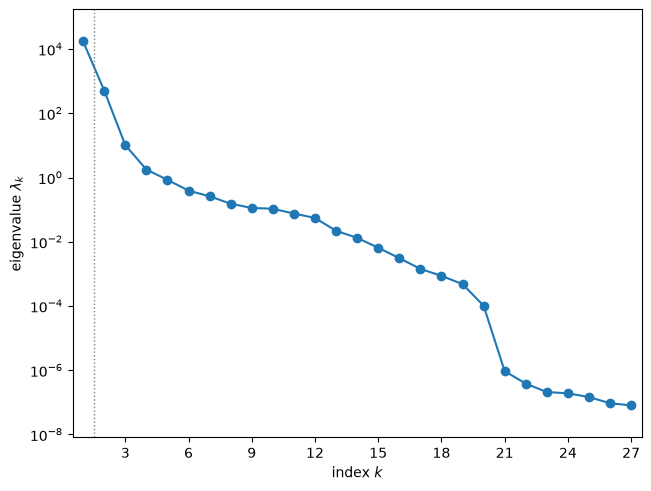

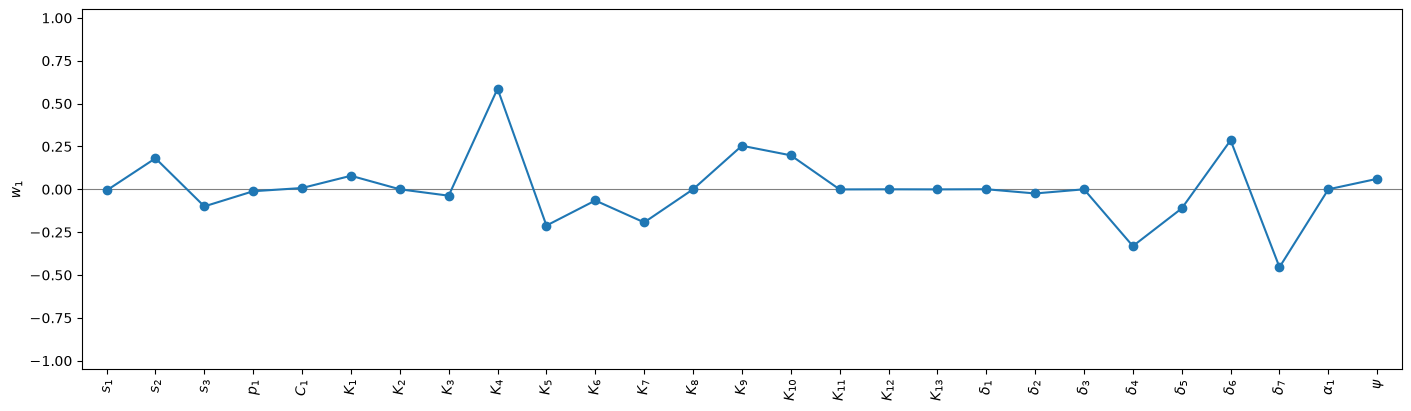

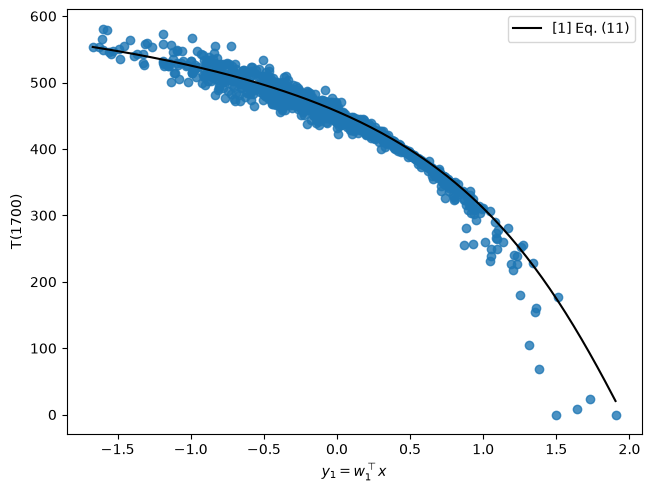

In [7]:
k = k_of[1700]
sub = subs[k]
lam, w = sub.eigenvalues, W1[k]
print(f't = 1700: {above[:, k].sum()} samples above the floor; lambda_1 = {lam[0]:.2e}, '
      f'lambda_2 = {lam[1]:.2e}, lambda_3 = {lam[2]:.1f}; '
      f'(lambda_1 - lambda_2)/lambda_1 = {(lam[0] - lam[1]) / lam[0]:.3f}')
print('paper Fig. 2 and Fig. 4 (read from the figures): lambda_1 ~ 1.5e+04, lambda_2 ~ 2e+03, '
      '(lambda_1 - lambda_2)/lambda_1 ~ 0.87')
print('|w1| > 0.3:', ', '.join(f'{names[j]} {w[j]:+.2f}' for j in np.flatnonzero(np.abs(w) > .3)))
paper_fig3 = {'K4': .58, 'delta4': -.33, 'delta7': -.46, 'delta6': .29, 'K9': .26}
print('w1 here vs paper Fig. 3 (read from the figure):',
      ', '.join(f'{p} {w[names.index(p)]:+.2f} ({v:+.2f})' for p, v in paper_fig3.items()))

# The paper's fit, Eq. (11), T(1700; y) = -79.2532 - 492.5680 arctan(0.8933 y - 1.9069),
# evaluated at y = w1^T x with this notebook's w1
y = space.to_normalized(X) @ w
T_fit = -79.2532 - 492.5680 * np.arctan(0.8933 * y - 1.9069)
err = np.abs(T_fit - f[:, k]) / f[:, k]
print(f'paper Eq. (11) vs the 1000 samples: relative error <= 5% for {np.mean(err <= .05):.0%} '
      f'(median {np.median(err):.1%})')

display(ac.plotting.plot_eigenvalues(sub)[0])
display(ac.plotting.plot_eigenvectors(sub, indices=[0], labels=labels, figsize=(14, 4))[0])
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f[:, k], dims=1, qoi_label='T(1700)')
ys = np.linspace(y.min(), y.max(), 200)
ax.plot(ys, -79.2532 - 492.5680 * np.arctan(0.8933 * ys - 1.9069), 'k-', label='[1] Eq. (11)')
ax.legend()
display(fig)

Three parameters have weights larger than 0.3 in absolute value, $K_4$, $\delta_4$ and $\delta_7$, as in [[1]](https://doi.org/10.3934/mbe.2017040) (p. 719, Fig. 3), and the other weights agree with Fig. 3 to the precision we can read it. The paper's fit, Eq. (11), is within 5% of $T(1700)$ for 91% of our 1000 samples, close to the paper's "over 90%" of 100 test runs. The first eigenvalue agrees with Fig. 2 in magnitude, but our second and later eigenvalues are smaller: $\lambda_2 = 509$ against about 2000 in Fig. 2, and $\lambda_3 = 10.2$. The paper's gradients were forward differences with step $10^{-6}$ on MATLAB `ode23s` solutions (pp. 717–718), and noise in such gradients adds to the small eigenvalues; we have not verified that this explains the difference.

### The AIDS stage: $t = 3400$ days

We'll plot eigenvalues, the first 2 eigenvectors, and 1- and 2-dimensional summary plots for the last time (3400 days). Only 526 samples are above the floor; the others are gray in the 1-D summary plot and left out of the 2-D one.

t = 3400: 526 of 1000 samples above the floor; lambda_1 = 8.622e+05, lambda_1/lambda_2 = 874; w1 top 4: K4 +0.65, delta7 -0.38, delta4 -0.35, K5 -0.28; K4 +0.655
with the samples at the floor included (gradient 0): lambda_1 = 4.535e+05, same eigenvectors


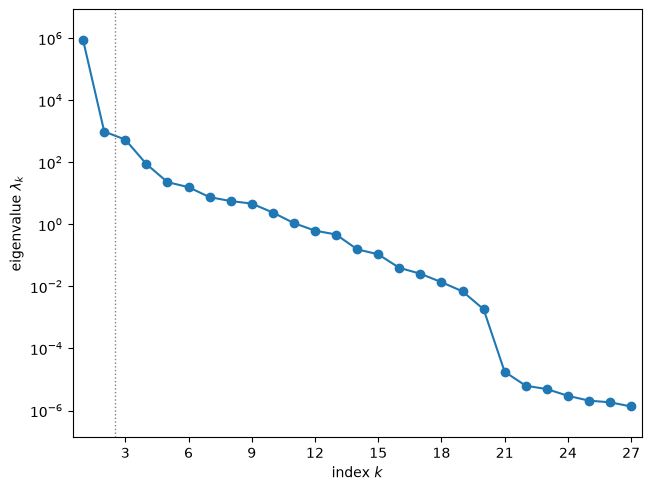

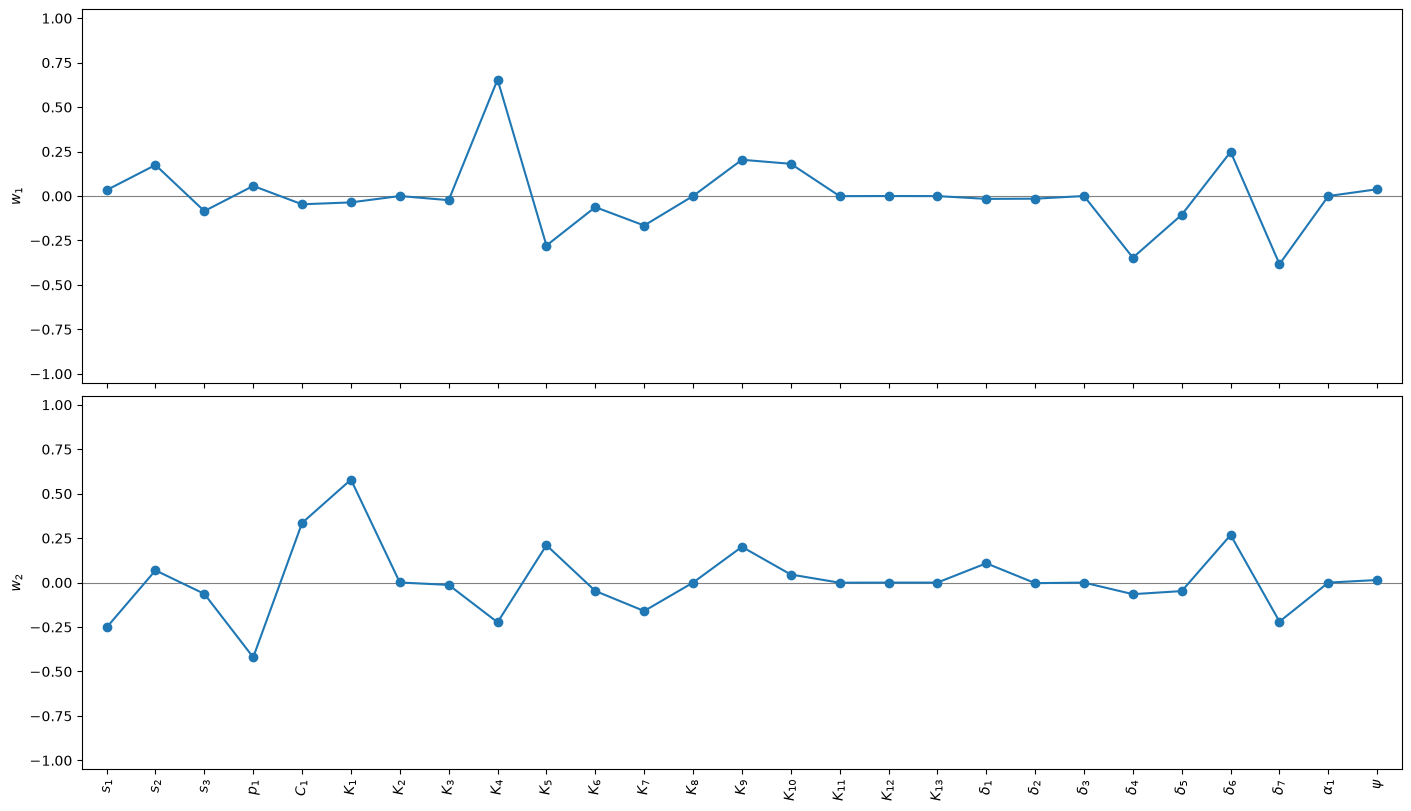

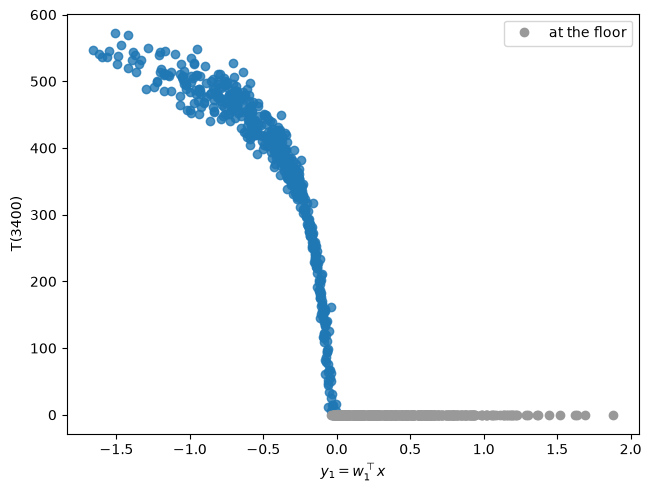

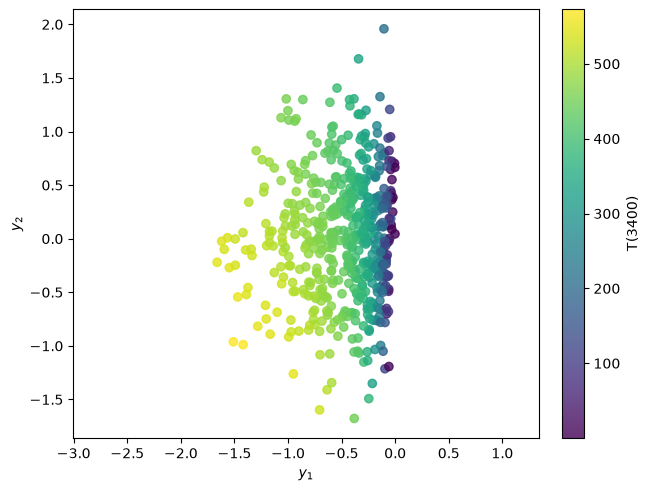

In [8]:
k = k_of[3400]
sub2 = ac.with_dimension(subs[k], 2)
lam, keep = sub2.eigenvalues, above[:, k]
print(f't = 3400: {keep.sum()} of {len(X)} samples above the floor; lambda_1 = {lam[0]:.3e}, '
      f'lambda_1/lambda_2 = {lam[0] / lam[1]:.0f}; w1 top 4: {top4(W1[k])}; K4 {W1[k, 8]:+.3f}')
print(f'with the samples at the floor included (gradient 0): lambda_1 = '
      f'{lam[0] * keep.mean():.3e}, same eigenvectors')

display(ac.plotting.plot_eigenvalues(sub2)[0])
display(ac.plotting.plot_eigenvectors(sub2, indices=[0, 1], labels=labels, figsize=(14, 8))[0])
fig, ax = ac.plotting.plot_sufficient_summary(sub2, X=X[keep], f=f[keep, k], dims=1,
                                              qoi_label='T(3400)')
ax.plot(XX[~keep] @ W1[k], f[~keep, k], 'o', color='0.6', label='at the floor')
ax.legend()
display(fig)
display(ac.plotting.plot_sufficient_summary(sub2, X=X[keep], f=f[keep, k], dims=2, qoi_label='T(3400)')[0])

The gap between the first and second eigenvalues ($\lambda_1/\lambda_2 = 874$) is not quite as large as at $t = 24$ (3954), and the smallest ratio is 30, at $t = 1600$. The summary plot shows more deviation from the trend. Different variables are important here (in the AIDS stage) than at the early time (the acute stage): $K_4$, $\delta_7$, $\delta_4$ and $K_5$ instead of $K_1$, $K_9$, $\delta_7$ and $\psi$. The eigenvalue-gap rule picks $n = 1$ at every one of the 19 times, including $t = 2000$ ($\lambda_1/\lambda_2 = 75$), so these data give no two-dimensional subspace at any time; the 2-D summary plot here is for illustration.

To illustrate the time-dependence of the active subspace, we plot the components of the first eigenvector as a function of time.

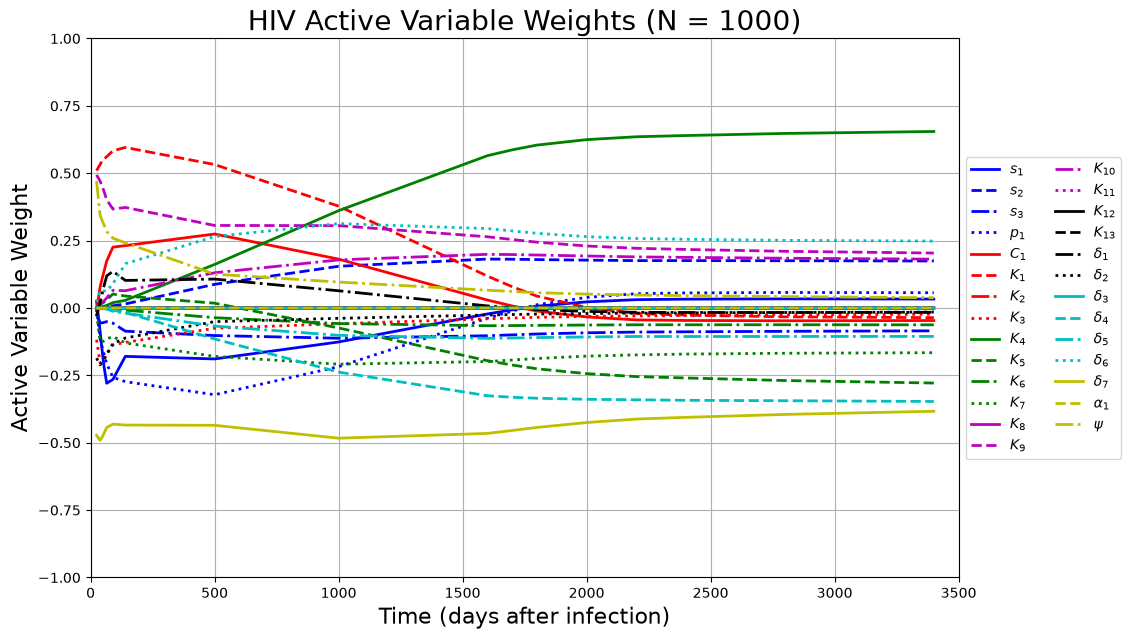

   t     K1     K4
  24  +0.51  +0.00
  38  +0.53  +0.00
  40  +0.54  +0.00
  45  +0.54  +0.00
  50  +0.55  +0.01
  55  +0.55  +0.01
  65  +0.56  +0.01
  90  +0.58  +0.02
 140  +0.60  +0.03
 500  +0.53  +0.16
1000  +0.38  +0.36
1600  +0.12  +0.57
1700  +0.08  +0.59
1800  +0.04  +0.60
2000  +0.00  +0.62
2200  -0.02  +0.64
2400  -0.03  +0.64
2800  -0.03  +0.65
3400  -0.04  +0.65


In [9]:
Colors = ['b', 'b', 'b', 'b', 'r', 'r', 'r', 'r', 'g', 'g', 'g', 'g', 'm', 'm', 'm',
          'm', 'k', 'k', 'k', 'k', 'c', 'c', 'c', 'c', 'y', 'y', 'y']
styles = ['-', '--', '-.', ':', '-', '--', '-.', ':', '-', '--', '-.', ':', '-', '--',
          '-.', ':', '-', '--', '-.', ':', '-', '--', '-.', ':', '-', '--', '-.']
plt.figure(figsize=(14, 7))
for j in range(27):
    plt.plot(TIMES, W1[:, j], color=Colors[j], linestyle=styles[j], linewidth=2, label=labels[j])
plt.xlim((0, 3500))
plt.ylim([-1, 1])
plt.grid(True)
plt.ylabel('Active Variable Weight', fontsize=16)
plt.xlabel('Time (days after infection)', fontsize=16)
box = plt.gca().get_position()
plt.gca().set_position([box.x0, box.y0, box.width * 0.8, box.height])
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=2)
plt.title('HIV Active Variable Weights (N = 1000)', fontsize=20)
plt.show()

print('   t     K1     K4')
for k, t in enumerate(TIMES):
    print(f'{t:4d}  {W1[k, 5]:+.2f}  {W1[k, 8]:+.2f}')

We can see that many parameters are important in some times and unimportant in others. For example, $K_4$ is unimportant in the acute stage (weight at most 0.03 up to $t = 140$) but very important in the chronic and AIDS stages (at least 0.57 from $t = 1600$), while $K_1$ is important in the acute and chronic stages (0.51–0.60 up to $t = 500$, 0.38 at $t = 1000$) but unimportant in the AIDS stage ($|w| \le 0.04$ from $t = 1800$). This agrees with [[1]](https://doi.org/10.3934/mbe.2017040) (p. 726), where $K_4$ is removed in the acute stage and has the largest weight at $t = 1700$.

Few variables have weight near zero for the entire course of the disease, so one can't significantly reduce the dimension of the parameter space globally in time by 'discarding' some parameters and setting them to nominal values. The cell below lists the parameters whose largest $|w_1|$ component over the 19 times is smallest.

In [10]:
wmax = np.abs(W1).max(axis=0)          # largest |w1| component over the 19 times
order = np.argsort(wmax)
print('max over the 19 times of |w1|, smallest ten:')
print(', '.join(f'{names[j]} {wmax[j]:.4f}' for j in order[:10]))

max over the 19 times of |w1|, smallest ten:
K8 0.0000, K12 0.0000, alpha1 0.0001, delta3 0.0001, K2 0.0004, K13 0.0005, K11 0.0013, K6 0.0658, s3 0.1122, delta5 0.1125


Seven parameters have $|w_1| \le 0.0013$ at all 19 times: $K_2$, $K_8$, $K_{11}$, $K_{12}$, $K_{13}$, $\delta_3$ and $\alpha_1$. The next smallest, $K_6$, reaches 0.0658. These seven could be fixed at their nominal values for the whole course of the disease. [[1]](https://doi.org/10.3934/mbe.2017040) (p. 726) concludes that "a true global-in-time parameter reduction is highly unlikely" and names at most three such parameters, $K_{11}$, $K_{12}$ and $K_{13}$; these data support the other four as well. This is a statement about $\mathbf w_1$ only, which is enough here because $n = 1$ at every time.

Finally, we compare the 20-sample subspaces from the finite-difference example with the 1000-sample ones at all 19 times, as $|\mathbf w_1^{(20)}\cdot\mathbf w_1^{(1000)}|$ (1 means the same direction). Samples at the floor are left out of both.

In [11]:
print('   t  N=20 above floor   |w1(20) . w1(1000)|')
for k, t in enumerate(TIMES):
    keep = fd[k].values > hm.T_FLOOR
    s = ac.active_subspace(space=space, grads=fd[k].grads_physical[keep])
    print(f'{t:4d}  {keep.sum():8d}            {abs(s.W[:, 0] @ W1[k]):.4f}')
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

   t  N=20 above floor   |w1(20) . w1(1000)|
  24        20            1.0000
  38        20            1.0000
  40        20            1.0000
  45        20            1.0000
  50        20            1.0000
  55        20            1.0000
  65        20            1.0000
  90        20            1.0000
 140        20            1.0000
 500        20            1.0000
1000        20            1.0000
1600        20            0.9998
1700        20            0.9991
1800        20            0.9990
2000        19            0.9981
2200        19            0.9999
2400        18            0.9999
2800        14            1.0000
3400         9            0.9973
Total run time: 77 s


The first eigenvectors from 20 samples agree with those from 1000 samples to at least 0.997 at every time, although only 9 of the 20 samples are above the floor at $t = 3400$. This indicates robustness in our results, and we might thus reasonably use these active subspaces for various applications, for example, global-in-time surrogate modelling or constraining an inverse problem.